In [1]:
import flopy
import numpy as np
import matplotlib.pyplot as plt
import xmf6
from src_02 import vis

In [2]:
# Usamos LaTeX para los tectos de la figura.
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Computer Modern Roman"],
})

[ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
 28.5 29.5]


In [14]:
o_sim_list = []
o_gwt_list = []
cspec_list = []
for i in range(1, 9):
    # Cargamos los modelos de transporte
    o_sim_list.append(flopy.mf6.MFSimulation.load(sim_ws=f"io_mf6/gwt{i}", verbosity_level=0))
    
    # Obtenemos los objetos de los modelos
    o_gwt_list.append(o_sim_list[i-1].get_model(f"transport{i}"))

    # Objetos para recuperar la concentración
    cspec_list.append(o_gwt_list[i-1].output.concentration())


In [36]:
# Recuperamos las coordenadas del dominio a partir de uno de los modelos
grid = o_gwt_list[0].modelgrid

# Recuperamos las coordenadas de los centros de las celdas de la malla
x = grid.xcellcenters[0] # centros de los volúmenes
print(x)

# Recuperamos los pasos de tiempo
times = np.asarray(cspec_list[0].get_times())

print(times[::10])

# Recuperamos la concentración
c_list = []

for c in cspec_list:
    c_list.append(c.get_alldata()[:, 0, 0, :])

[ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
 28.5 29.5]
[0.01 0.11 0.21 0.31 0.41 0.51 0.61 0.71 0.81 0.91 1.01 1.11 1.21 1.31
 1.41 1.51 1.61 1.71 1.81 1.91 2.01 2.11 2.21 2.31 2.41 2.51 2.61 2.71
 2.81 2.91 3.01 3.11 3.21 3.31 3.41 3.51 3.61 3.71 3.81 3.91 4.01 4.11
 4.21 4.31 4.41 4.51 4.61 4.71 4.81 4.91]


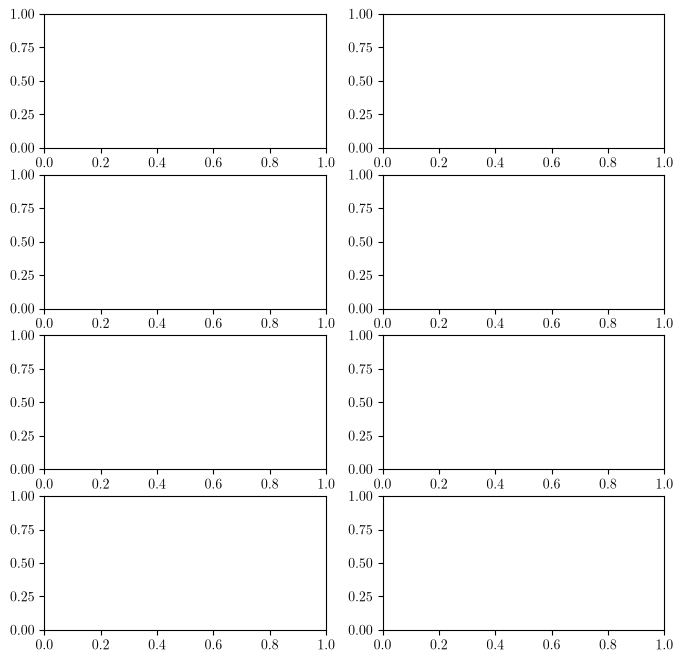

In [37]:
fig, axes = plt.subplots(4, 2, figsize=(8, 8))
ax = axes.flat

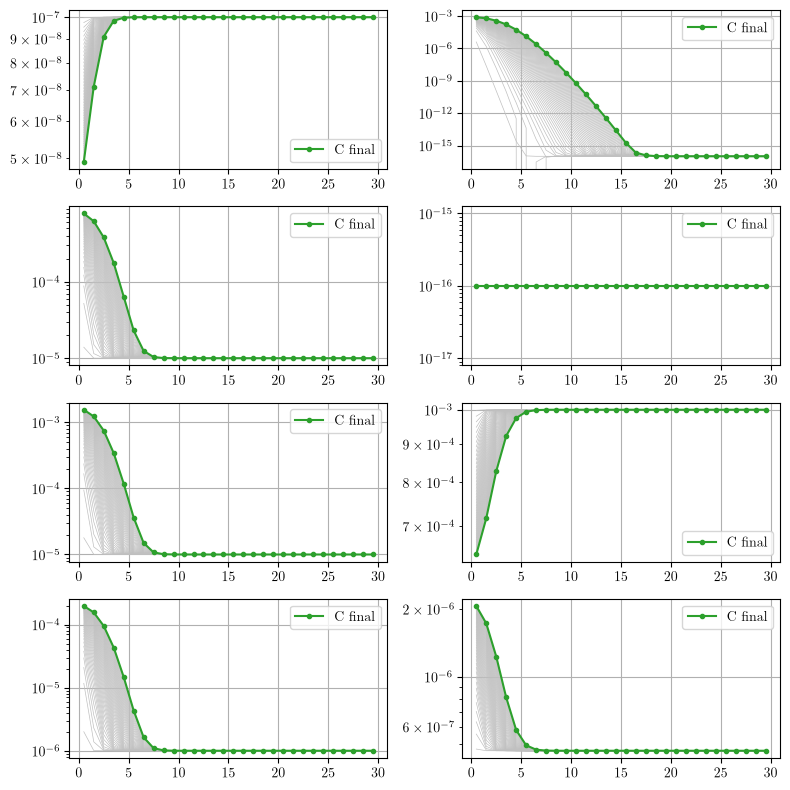

In [38]:
fig, axes = plt.subplots(4, 2, figsize=(8, 8))
ax = axes.flat
#ax.plot(x, c1[0], lw=1.5, ls = "-", marker = ".", color='C1', label = "C inicial")

for n, c in enumerate(c_list):
    for ci in c[::10]:
        ax[n].plot(x, ci, lw=.5, color='silver')
    
    ax[n].plot(x, c[-1], lw=1.5, ls = "-", marker = ".", color='C2',  label = "C final")
    
    #ax.set_title(f"c = {species["names"][m]}")
    ax[n].set_yscale("log")
    ax[n].grid()
    
    ax[n].legend()

plt.tight_layout()
plt.show()
